# NSSP part 1

Practicals - Part 1 
Using what you learnt in the lab sessions   

**1) Structural preprocessing: Apply the following steps using the methods of 
your choice (e.g., fMRIPrep, FSL-based, python-based):**  

a) Skull-stripping. Report and plot the original T1w image and the 
skull-stripped brain to visually assess the quality of the brain extraction.   

b) Segmentation. Report and plot the segmented tissues on the brain.   

c) Registration. Register your results bringing them to MNI space.   
Report a plot of the T1 alignment with MNI before and after this step.   

**2) Functional preprocessing: Apply the following steps using the methods of 
your choice (e.g., fMRIPrep, FSL-based, python-based):** 

a) Motion correction (you can take care of the irregular volumes the way 
you want). Report and plot the framewise displacement and comment 
on the results.   

b) Gaussian smoothing with an appropriate FWHM. Report the brain 
plot of a single fMRI volume of your choice before and after smoothing.    

c) Validate the alignment between anatomical and functional data.   
Overlay the fMRI to the structural data that you previously registered to 
MNI space. Report a plot of the overlay at one fMRI volume and 
section of your choice and comment on the general quality of the 
alignment. Is there a fMRI preprocessing step that can be avoided 
given what you see? Justify your answer based on the plot. 

Briefly justify in your report the purpose of each of the structural and functional preprocessing steps. 

# 0. imports

In [29]:
###################
# Load all relevant libraries for the lab
##################
import fsl.wrappers
from fsl.wrappers import fslmaths

import mne_nirs
import nilearn
from nilearn.datasets import fetch_development_fmri

import mne
import mne_nirs
import dipy
from dipy.data import fetch_bundles_2_subjects, read_bundles_2_subjects
import xml.etree.ElementTree as ET
import os.path as op
import nibabel as nib
import glob

!pip install antspyx
import ants

import openneuro
from mne.datasets import sample
from mne_bids import BIDSPath, read_raw_bids, print_dir_tree, make_report

# Useful imports to define the direct download function below
import requests
import urllib.request
from tqdm import tqdm


# FSL function wrappers which we will call from python directly
from fsl.wrappers import fast, bet
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

# General purpose imports to handle paths, files etc
import glob
import pandas as pd
import numpy as np
import json
import subprocess

  Using cached antspyx-0.6.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (7.2 kB)
  Using cached numpy-2.3.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached scipy-1.15.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached antspyx-0.6.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (22.4 MB)
Using cached numpy-2.3.5-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.6 MB)
Using cached scipy-1.15.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
ERROR: Could not install packages due to an OSError: [Errno 13] Permission denied: '/opt/conda/lib/python3.13/site-packages/numpy-2.5.4.dist-info/'
Consider using the `--user` option or check the permissions.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3 [numpy]


ModuleNotFoundError: No module named 'ants'

In [3]:
import sys
import os

notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist, interactive_MCQ

# project directories
data_dir =  "/home/jovyan/data/tsclient/NSSP/progetto"
output_dir = "/home/jovyan/data/tsclient/NSSP/progetto/outputs/structural"

print("Notebook directory:", notebook_dir)
print("Project directory:", parent_dir)
print("Data directory:", data_dir)
print("Output directory:", output_dir)

os.environ["DIPY_HOME"] = "/home/jovyan/tsclient/dipy_data"


print(os.path.isdir(data_dir))
print(os.listdir(data_dir))

import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()



Notebook directory: /data/Desktop/myfiles/NSSP_project_1/notebooks
Project directory: /data/Desktop/myfiles/NSSP_project_1
Data directory: /home/jovyan/data/tsclient/NSSP/progetto
Output directory: /home/jovyan/data/tsclient/NSSP/progetto/outputs/structural
True
['.ipynb_checkpoints', 'dataset_description.md', 'fMRI-20261015T140819Z-1-001', 'fMRI-20261015T140819Z-1-001.zip', 'outputs', 'part1.ipynb', 'per copiare.txt', 'T1-20261015T140821Z-1-001', 'T1-20261015T140821Z-1-001.zip']


['fsl/6.0.7.18', 'freesurfer/7.4.1']

In [4]:
# setup FSL path
loadFSL()

In [5]:
%gui wx


(ipykernel_launcher.py:1739): dbind-WARNING **: 16:11:55.517: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/203554217/at-spi/bus_100: No such file or directory


In [6]:
# Start FSLeyes 
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

16:11:57: Debug: Adding duplicate image handler for 'Windows bitmap file'
16:11:57: Debug: Adding duplicate animation handler for '1' type
16:11:57: Debug: Adding duplicate animation handler for '2' type
16:11:57: Debug: Adding duplicate image handler for 'Windows bitmap file'
16:11:57: Debug: Adding duplicate animation handler for '1' type
16:11:57: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:1739): Gtk-CRITICAL **: 16:11:58.135: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1739): Gtk-CRITICAL **: 16:12:00.165: gtk_window_resize: assertion 'width > 0' failed


In [7]:
import os
import glob

# Find structural T1w image
t1_files = glob.glob(
    os.path.join(data_dir, "T1-*", "T1", "T1w.nii.gz"),
    recursive = True
)


# Check input
if len(t1_files) != 1:
    raise ValueError(f"Expected one T1w image, found: {t1_files}")

t1_path = t1_files[0]

# Create output folder
os.makedirs(output_dir, exist_ok=True)

# Verify paths
print("Project exists:", os.path.isdir(parent_dir))
print("Data exists:", os.path.isdir(data_dir))
print("Input T1w:", t1_path)
print("Output directory:", output_dir)


Project exists: True
Data exists: True
Input T1w: /home/jovyan/data/tsclient/NSSP/progetto/T1-20261015T140821Z-1-001/T1/T1w.nii.gz
Output directory: /home/jovyan/data/tsclient/NSSP/progetto/outputs/structural


In [8]:
import os
import glob

# Search recursively for T1 images
t1_files = glob.glob(
    os.path.join(data_dir, "**", "*T1*.nii.gz"),
    recursive=True
)

print("T1 images found:")
print(t1_files)

T1 images found:
['/home/jovyan/data/tsclient/NSSP/progetto/T1-20261015T140821Z-1-001/T1/T1w.nii.gz']


1. anatomical preprocessing

In [9]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(t1_path) # load the T1w image

1.1 skull stripping

In [15]:
def get_skull_stripped_anatomical(t1_path, output_path, robust=False):
    """
    Function to perform skull-stripping (removing the skull around the brain).
    This is a simple wrapper around the brain extraction tool (BET) in FSL's suite
    It assumes data to be in the BIDS format (which we will cover in the following weeks).
    The method also saves the brain mask which was used to extract the brain.

    The brain extraction is conducted only on the T1w of the participant.

    Parameters
    ----------
    t1_path: string
        Path to the original T1w image.
    output_dir: string
        Directory where preprocessing results are saved.
    robust: bool
        Whether to conduct robust center estimation with BET or not. Default is False.

    Outputs
    -------
    T1w_brian.nii.gz 
        skull-stripped anatomical image
    T1w_brain_mask.nii.gz 
        binary brain mask
    """
    # output directory 
    os.makedirs(output_dir, exist_ok= True)

    # output path
    betted_brain_path = os.path.join(output_dir, "T1w_brain.nii.gz")
    
    # run BET
    os.system('bet {} {} -m {}'.format(t1_path, betted_brain_path, '-R' if robust else ''))
    print("Done with BET.")

# resulting mask path
resulting_mask_path = os.path.join(output_dir, "T1w_brain_mask.nii.gz")

# perform skull stripping 
get_skull_stripped_anatomical(t1_path, output_dir)

# visualize 
fsleyesDisplay.load(resulting_mask_path)

Done with BET.


In [18]:
# visualize the skull-stripped brain
brain_path = os.path.join(output_dir, "T1w_brain.nii.gz")
# reset overlayes
fsleyesDisplay().resetOverlays()
# load skull-stripped brain
fsleyesDisplay.load(brain_path)

TypeError: 'FSLeyesServer' object is not callable

improving the fit --> a me non sembra necessario

In [ ]:
#get_skull_stripped_anatomical(bids_root, preproc_root, "001", robust=True)
#fsleyesDisplay.resetOverlays()
#fsleyesDisplay.load(op.join(bids_root, 'sub-001', 'anat', 'sub-001_T1w.nii.gz'))
#fsleyesDisplay.load(resulting_mask_path)

nel caso fare manual correction come nel lab2

apply the mask

In [21]:
def apply_fsl_math_approach(img_path, mask_path, masked_img_path):
    os.system('fslmaths {} -mas {} {}'.format(img_path, mask_path, masked_img_path))
    

anatomical_path = t1_path # The original brain
resulting_mask_path= op.join(output_dir, "T1w_brain_mask.nii.gz") # The brain without skull is in the derivatives folder
masked_img_path = op.join(output_dir, "T1w_masked_fsl.nii.gz") # The mask to use


apply_fsl_math_approach(anatomical_path, resulting_mask_path, masked_img_path)


## vizualize
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(masked_img_path)

To compare the different images

In [22]:
anatomical_path = t1_path # original T1w
resulting_brain_mask= os.path.join(output_dir, "T1w_brain_mask.nii.gz") # binary mask
betted_brain_path = os.path.join(output_dir, "T1w_brain.nii.gz") # skull-tripped T1
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(anatomical_path)
fsleyesDisplay.load(betted_brain_path)
fsleyesDisplay.load(resulting_brain_mask)

1.2 tissue segmentation

In [25]:
anatomical_path = t1_path
bet_path = os.path.join(output_dir, "T1w_brain.nii.gz")


fast_target = bet_path 

[os.remove(f) for f in glob.glob(op.join(output_dir, "T1w_fast*"))] # Just to clean the directory in between runs of the cell
segmentation_path = op.join(output_dir, "T1w_fast")
fast(imgs=[fast_target], out=segmentation_path, n_classes=3)

print_dir_tree(output_dir, max_depth=5)



|structural/
|--- T1w_brain.nii.gz
|--- T1w_brain_mask.nii.gz
|--- T1w_fast_mixeltype.nii.gz
|--- T1w_fast_pve_0.nii.gz
|--- T1w_fast_pve_1.nii.gz
|--- T1w_fast_pve_2.nii.gz
|--- T1w_fast_pveseg.nii.gz
|--- T1w_fast_seg.nii.gz
|--- T1w_masked_fsl.nii.gz


NameError: name 'fslEyesDisplay' is not defined

In [26]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(bet_path)
fsleyesDisplay.load(glob.glob(os.path.join(output_dir, '*pve_0*'))[0])
fsleyesDisplay.load(glob.glob(os.path.join(output_dir, '*pve_1*'))[0])
fsleyesDisplay.load(glob.glob(os.path.join(output_dir, '*pve_2*'))[0])
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[1]).cmap = 'Red'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[2]).cmap = 'Green'
fsleyesDisplay.displayCtx.getOpts(fsleyesDisplay.overlayList[3]).cmap = 'Blue'

1.3 registration

In [27]:
# visualize data

import threading

def launch_freeview(img_list):
    """
    Wrapper around freeview to launch it with several images.
    This wrapper is necessary to launch freeview in a separate thread, ensuring the notebook is free to do something else.

    Parameters
    ----------
    img_list: list of string
        List of images (files) to load. Assumed by default to be volume files.
    """
    args = []
    
    for i in range(len(img_list)):
        args.append("-v")
        args.append(img_list[i])
    # Run the command
    subprocess.run(["freeview"] + args)

imgList = [op.expandvars('$FSLDIR/data/standard/MNI152_T1_1mm.nii.gz'), 
           op.join(output_dir, "T1w_brain.nii.gz:colormap=greyscale")] 
freeview_thread = threading.Thread(target=launch_freeview, args=(imgList,)) # Remark the (imgList,) when passing to args. This is very important to make Thread work properly

# Start the thread
freeview_thread.start()

print("Freeview is running in a separate thread.")

Freeview is running in a separate thread.


QStandardPaths: XDG_RUNTIME_DIR not set, defaulting to '/tmp/runtime-jovyan'


linear normalization

In [28]:
from fsl.wrappers import flirt

# The two images
subject_anatomical =op.join(output_dir, "T1w_brain")
mni_template = op.expandvars(op.join('$FSLDIR', 'data', 'standard', 'MNI152_T1_1mm_brain'))

print("Subject:", subject_anatomical)
print("MNI template:", mni_template) 

###################
# Select which image should be source or reference
# ANSWER:
# The subject anatomical will most often be the source, as the template is usually where we want to map our subjects for 
# group comparison.
# There are cases, however, where we may want the subject anatomical to be the reference. This is the case when we want to map an 
# atlas to a subject while preserving the subject as much as possible.
# We showcase here the case where the subject is chosen as source.
#Please note that the values in the transformation matrix of flirt refer to:
#Top-left 3×3 block: rotation, scaling, shearing.
#Last column: translation in x, y, z.
#Bottom row: always [0 0 0 1] for affine transforms.
##################
source = subject_anatomical 
reference = mni_template 
result = op.join(output_dir, "T1w_mni")
flirt(source, reference, out=result)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(reference) 
fsleyesDisplay.load(result)


# choose a cost
# Solution
# We consider only within-modalities costs, as the two images belong to the same modality: least squares and normalized correlation ratio.
# Remark correlation ratio also technically works
# So FSL FLIRT offers several cost functions for image registration. Mutual information measures statistical dependence between image intensity distributions. Correlation ratio evaluates how well one image can predict another using conditional variance statistics. Normalized correlation measures linear correlation between image intensities using the Pearson correlation coefficient. Normalized mutual information provides a scale-independent version of mutual information. Least squares minimizes squared intensity differences by assuming corresponding voxels should have similar intensities. Label difference minimizes mismatched labels for discrete segmentation images. Each function makes different assumptions about the relationship between corresponding image intensities.
#######
possible_costs = ['mutualinfo', 'corratio', 'normcorr', 'normmi', 'leastsq', 'labeldiff']
costs_to_consider = [ 'leastsq', 'normcorr' ] # fill me with the relevant costs

for c in costs_to_consider:
    flirt(source, reference, out=result + '_' + c, cost=c)

for c in costs_to_consider:
    fsleyesDisplay.load(result + '_' + c)

Subject: /home/jovyan/data/tsclient/NSSP/progetto/outputs/structural/T1w_brain
MNI template: /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18//data/standard/MNI152_T1_1mm_brain

Final result: 
1.080069 -0.016103 0.008044 -6.138958 
0.024908 1.122695 -0.006892 -16.474805 
-0.021891 -0.011482 1.193937 -8.884435 
0.000000 0.000000 0.000000 1.000000 


Final result: 
1.165977 -0.026233 0.011904 -13.112515 
0.025651 1.226179 -0.029632 -26.099970 
-0.014613 -0.023743 1.450502 -29.062251 
0.000000 0.000000 0.000000 1.000000 


Final result: 
1.072263 -0.015859 0.008022 -5.485179 
0.025935 1.114739 -0.006483 -15.820878 
-0.021196 -0.010024 1.181492 -8.108135 
0.000000 0.000000 0.000000 1.000000 



non linear normalization

In [30]:
moving_image = ants.image_read(source + '.nii.gz')
fixed_image = ants.image_read(reference + '.nii.gz')

# Compute the transformation (non linear) to put align the moving image to the fixed image
transformation = ants.registration(fixed=fixed_image, moving=moving_image, type_of_transform = 'SyN' )

# After the transformation has been computed, apply it
warpedImage = ants.apply_transforms(fixed=fixed_image, moving=moving_image, transformlist=transformation['fwdtransforms'])

# Save the image to disk
resultAnts = op.join(output_dir, "T1w_mni_SyN.nii.gz")
ants.image_write(warpedImage, resultAnts)

# Inspect the results with FSLeyes or freeview, as you prefer :)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(reference)
fsleyesDisplay.load(result)
fsleyesDisplay.load(resultAnts)

NameError: name 'ants' is not defined

alla fine del lab 2 dice che ci sono altri step che si possono fare. 

In [ ]:
"""os.system('fsl_anat')
import shutil

def fsl_anat_wrapped(anatomical_target, output_path):
    os.system('fsl_anat -i {} --clobber --nosubcortseg -o {}'.format(anatomical_target,output_path))
    # Now move all files from the output_path.anat folder created by FSL to 
    # the actual output_path
    fsl_anat_path = output_path+'.anat'
    files_to_move = glob.glob(op.join(fsl_anat_path, '*'))
    for f in files_to_move:
        shutil.move(f, op.join(output_path, op.split(f)[1]))
    
    # Remove the output_path.anat folder
    os.rmdir(fsl_anat_path)

print_dir_tree(bids_root, max_depth=5)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.expandvars(op.join('$FSLDIR', 'data', 'standard', 'MNI152_T1_1mm')))
fsleyesDisplay.load(op.join(preproc_root, 'sub-001', 'anat', 'T1_to_MNI_lin'))
fsleyesDisplay.load(op.join(preproc_root, 'sub-001', 'anat', 'T1_to_MNI_nonlin'))"""

2. functional preprocessing

2.1 motion correction

problematic volume removal 

In [33]:
import subprocess

fmri_path = os.path.join(data_dir, "fMRI-20261015T140819Z-1-001", "fMRI", "tfMRI_LANGUAGE_LR", "tfMRI_LANGUAGE_LR.nii.gz")

print("Functional MRI exists:", os.path.isfile(fmri_path))
print("Functional MRI path:", fmri_path)

# functional preprocessing output directory
func_output_dir = os.path.join(data_dir, "outputs", "functional")
os.makedirs(func_output_dir, exist_ok= True)

fmri_img = nib.load(fmri_path)


Functional MRI exists: True
Functional MRI path: /home/jovyan/data/tsclient/NSSP/progetto/fMRI-20261015T140819Z-1-001/fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz


field stabilization

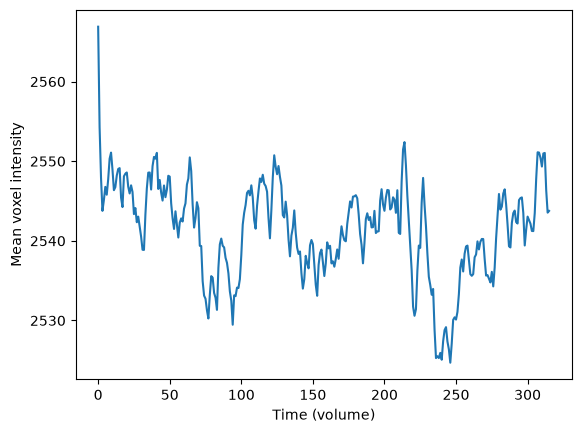

In [34]:
import matplotlib.pyplot as plt
import nibabel as nib

plt.plot(nib.load(fmri_path).get_fdata().mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.show()

In [38]:
file_to_trim = fmri_path
# output functional directory 
func_output_dir = op.join(data_dir, 'outputs', 'functional')
mkdir_no_exist(func_output_dir)

# output image
output_target = op.join(func_output_dir, 'tfMRI_LANGUAGE_LR_settled.nii.gz')

# total numeber of volumes
total_volumes = nib.load(file_to_trim).shape[-1]
# remove first volumes --> dall'immagine sopra vediamo che il volume più problematico è il primo 

start_vol = 1 # Where should we start? (First volume is 0, not 1 !)
number_of_volumes = total_volumes - start_vol # How many volumes should we keep?

# Function creating new nifti with trimmed number of volumes
fslroi(file_to_trim, output_target, str(start_vol), str(number_of_volumes))
print(f"You kept {nib.load(output_target).shape[-1]} volumes.")

You kept 315 volumes.


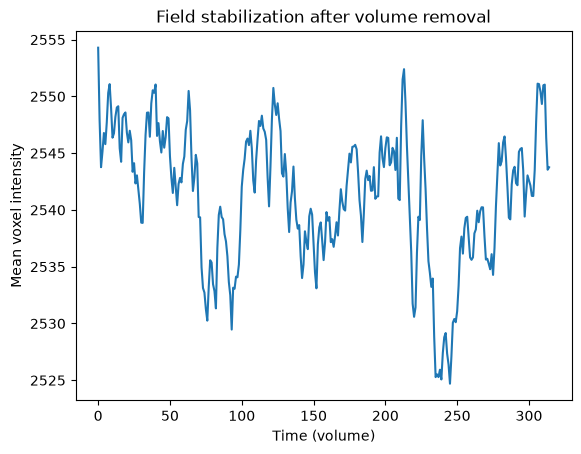

In [40]:
# Mean voxel intensity after removing the first volume
plt.plot(nib.load(output_target).get_fdata().mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')
plt.title('Field stabilization after volume removal')
plt.show()

motion correction

In [42]:
from fsl.wrappers import mcflirt

# input fMRI after volume removal 
path_original_data = output_target

# output motion-corrected fMRI
path_moco_data = op.join(func_output_dir, "tfMRI_LANGUAGE_LR_moco")

# motion correction
mcflirt(infile=path_original_data,o=path_moco_data, plots=True, report=True, dof=6, mats=True)
print("Morion correction completed")

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(path_original_data)
fsleyesDisplay.load(path_moco_data)

Processed data will be saved as /home/jovyan/data/tsclient/NSSP/progetto/outputs/functional/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [157] to 8 mm pixels
Registering volumes ... [158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][29

refnum = 157
Original_refvol = -1


Registering volumes ... [158][159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][311][312][313][314][156][155][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][119][

Morion correction completed


looking at the resulting correction parameters

In [43]:
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(path_moco_data + ".par")
mot_params

,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z
0,0.000163,0.000492,-0.000059,0.030005,-0.038251,0.059965
1,-0.000031,0.000411,-0.001100,0.012959,-0.025233,0.051918
2,0.000297,-0.000309,-0.000091,-0.042305,-0.029215,0.039045
3,0.000089,-0.000224,-0.000001,-0.034639,-0.014459,0.047900
4,0.000297,-0.000207,0.000030,-0.034579,-0.014456,0.051957
...,...,...,...,...,...,...
310,0.000637,0.000457,-0.000409,0.033171,-0.017516,0.041027
311,0.000274,0.000454,-0.000409,0.045505,-0.026485,0.045447
312,0.000977,0.000258,-0.000409,0.042573,-0.009193,0.022216
313,-0.000272,0.000792,-0.000409,0.041113,0.025147,0.021226


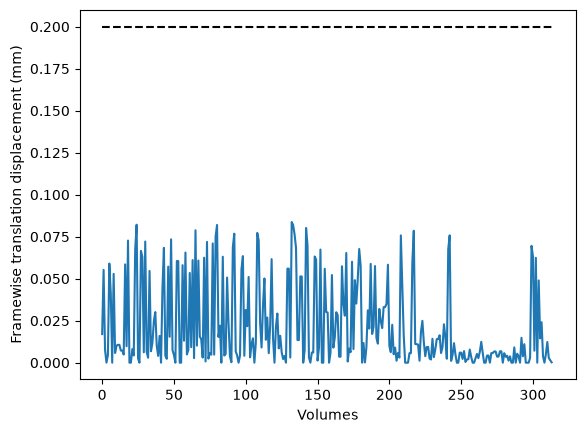

In [44]:
# Getting the translation 
trans_x = mot_params["Translation x"]

# Now, we want a 0.2mm with respect to previous frame:
disp_x = np.diff(trans_x)
# Lastly, we can ask for displacements (in absolute value) above 0.2mm and plot it to be clear:
threshold=0.2
plt.plot(np.abs(disp_x))
plt.hlines(threshold, 0, len(disp_x) ,colors='black', linestyles='dashed', label='FD threshold')
plt.xlabel("Volumes")
plt.ylabel("Framewise translation displacement (mm)")
plt.show()

# There are basically (if looking only along X translation) no frame displacement above 0.2mm!

Some metrics have been created, to compute the displacement of a frame compared to the preceding frame: this is the **frame-wise displacement**. While considering the x-translation can be indicative of motion, it omits displacement in other directions. Here the **frame-wise displacement** allows to quantify overall displacements. <br>(see [Power, Jonathan D., et al. "Spurious but systematic correlations in functional connectivity MRI networks arise from subject motion." Neuroimage 59.3 (2012): 2142-2154](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3254728/) for more details).<br>
We can use this one to extract an aggregate measure of motion for all volumes. 

In [ ]:
def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere
    # To know this one, we can remember the definition of the radian!
    # Indeed, let the radian be theta, the arc length be s and the radius be r.
    # Then theta = s / r
    # We want to determine here s, for a sphere of 50mm radius and knowing theta. Easy enough!
    
    # Another way to think about it is through the line integral along the circle.
    # Integrating from 0 to theta with radius 50 will give you, unsurprisingly, r0 theta.
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

fd = compute_FD_power(mot_params).to_numpy()

threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))

#%matplotlib inline
plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.hlines(threshold, 0, 370,colors='black', linestyles='dashed', label='FD threshold')
plt.legend()
plt.show()

#Okay great, but what if we want to know which volumes are actually above threshold? Simply run the cell below!
print(f"Indices of frames above threshold: {(np.where(fd > threshold)[0] + 1).tolist()}")

EPI-to-T1 registration

use EPI to fo registration
Fill in the name of the EPI source. It should be the motion-corrected EPI that you corrected using MCFLIRT. If you want to use a single volume, set the use_first_vol variable to True!

Fill in the path to the whole head T1 image (before skull stripping was conducted!)

Fill in the path to the skull-stripped T1 image (after skull stripping was conducted!)

In [ ]:
# Important: Remember to generate skull stripped T1 and perform tissue segmentation if you did not yet !!! Hint: Use skull stripping and segmentation function from Lab 2!

# Generate skull stripped T1
anatomical_path = op.join(bids_root, 'sub-001', 'anat', 'sub-001_T1w.nii.gz')
betted_brain_path = op.join(preproc_root, 'sub-001', 'anat', 'sub-001_T1w')
os.system('bet {} {} -m {}'.format(anatomical_path, betted_brain_path, ''))

# Generate segmented tissues
[os.remove(f) for f in glob.glob(op.join(preproc_root, 'sub-001', 'anat', '*fast*'))] # Just to clean the directory in between runs of the cell
segmentation_path = op.join(preproc_root, 'sub-001', 'anat', 'sub-001_T1w_fast')
fast(imgs=[betted_brain_path], out=segmentation_path, n_classes=3)


subprocess.run(['epi_reg'])


# epi_reg has one peculiarity. If you launch it on a 4D volume, it will truncate your result to the first volume, because it expects a single EPI volume. We should thus first extract a single volume from our EPI, and then call epi_reg on it. We do that for you below.
# If you want to run with 4D volume to see the result and the warning, set use_single_vol to False

from fsl.wrappers import epi_reg

#################
# Solution
# We use the motion corrected EPI 
##################

# We use the motion corrected EPI
epi_source = op.join(preproc_root, 'sub-001', 'func', 'sub-001_task-sitrep_run-01_bold_moco')
whole_t1 = op.join(bids_root, 'sub-001', 'anat', 'sub-001_T1w')
skull_stripped_t1 = op.join(preproc_root, 'sub-001', 'anat', 'sub-001_T1w')
output_path = op.join(preproc_root, 'sub-001', 'func', 'sub-001_task-sitrep_run-01_bold_bbr')
ref_vol_name =  op.join(preproc_root, 'sub-001', 'func', 'sub-001_task-sitrep_run-01_bold_moco_vol_middle')

use_single_vol = True

if use_single_vol:
    # Extract the middle volume with fslroi as we've seen before :)
    fslroi(epi_source, ref_vol_name, str(182), str(1))
    # Call epi_reg
    subprocess.run(['epi_reg','--epi={}'.format(ref_vol_name), '--t1={}'.format(whole_t1), '--t1brain={}'.format(skull_stripped_t1), '--out={}'.format(output_path)])
else:
    subprocess.run(['epi_reg','--epi={}'.format(epi_source), '--t1={}'.format(whole_t1), '--t1brain={}'.format(skull_stripped_t1), '--out={}'.format(output_path)])

Notice how FAST is ran?
This is because the specific coregistration cost (boundary-based registration, BBR) uses the anatomical white-matter tissues from FAST. If no such tissue is provided to the function, it re-runs FAST to obtain it and use it. If you've already done anatomical segmentation, clearly there's no need to redo it right?
In particular, imagine if you had to yourself correct the white matter with the help of an expert because somehow FSL did a poor job on your data. Clearly you'd like to have this one used instead of the result from FAST, right?

Well- you can! We just need a new option in the epi_reg command:
```python
epi_reg(...,wmseg=path_to_your_white_matter_segmentation)
```
Remember from last week, which T1 file corresponds to the white matter, between pve_0, pve_1 and pve_2 ? Put it as your white matter segmentation. (Note: of course, you will need to re-do your T1 segmentation before you can feed it here - a good moment to remember the previous week and revisit FAST and BET ;) )

In [ ]:
###############
# Solution
# White matter corresponds to pve_2.
##############

white_matter_segmentation = op.join(preproc_root, 'sub-001', 'anat', 'sub-001_T1w_fast_pve_2.nii.gz') # We provide the white matter segmentation

subprocess.run(['epi_reg','--epi={}'.format(ref_vol_name), '--t1={}'.format(whole_t1), '--t1brain={}'.format(skull_stripped_t1), 
                '--out={}'.format(output_path),
               '--wmseg={}'.format(white_matter_segmentation)])



fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(skull_stripped_t1)
fsleyesDisplay.load(output_path)

#### 1.5.2 Some cleanup
If you have a look, you might notice that perhaps your directory got filled with many files. These are temporary files, created but uncorrectly not eliminated by epi_reg. The following should help:

In [ ]:
def cleanup_epi_reg(path_to_clean):
    patterns = ['*_fast_*', '*_fieldmap*']
    for p in patterns:
        files = glob.glob(op.join(path_to_clean, p))
        for f in files:
            os.remove(f)

cleanup_epi_reg(op.join(preproc_root, 'sub-001', 'func'))
print_dir_tree(bids_root, max_depth=5)

2.2 gaussian smoothing

## 1.6 Smoothing
All these transforms are not exactly perfect. As you've seen in class, a step of smoothing is typically applied, with the size of the smoothing being dependent on your application, starting resolution etc.
The idea of smoothing is really that, as you're averaging, hopefully you increase the signal to noise ratio. <br>
A side-effect is that finest patterns of activation will be lost in the averaging (we can't have everything: there's no free lunch).

With FSL, smoothing is rather easy to do. However, one thing which is important is the size of your filter.
Different softwares might use different conventions. For MRI, it is typical to talk about FWHM (Full-width at half maximum), expressed in mms.

FSL, however, takes as input in sigma instead of FWHM. The conversion is easy fortunately:

$$ \sigma = \frac{FWHM}{2.3548}$$

Here for example would be the smoothing command for 6mm FWHM smoothing:

In [ ]:
cmd = 'fslmaths {} -s {} {}_smoothed-6mm'.format(output_path, 6/2.3548, output_path)
subprocess.run(['fslmaths',output_path, '-s', str(6/2.3548), '{}_smoothed-6mm'.format(output_path)])
fsleyesDisplay.load(output_path + '_smoothed-6mm')